# 06. CLV hai phần (Task 9)

**Bài toán:** nếu giữ được khách thì khách mang về bao nhiêu lợi nhuận trong 12 tháng tới (`CLV_giữ_được`). Mô hình hai phần (hurdle):

- **Phần 1** = model churn đã đóng băng ở Task 6 (`churn_model.fit_final()`), không train lại.
- **Phần 2** = `CLV_giữ_được`, **chỉ fit trên khách có quay lại** (`churn = 0`).
- `CLV_kỳ_vọng = (1 − p_churn) × CLV_giữ_được`, dùng để so với hồi quy một phần trên toàn bộ khách.

Notebook đi theo đúng quá trình làm:

1. **Bước thử (mục 1–7):** OLS hồi quy thẳng lên lợi nhuận gộp, mục tiêu `slog(y) = sign(y)·log(1+|y|)` + smearing. Kết quả: lợi nhuận gần như không đoán được.
2. **Chẩn đoán (mục 8):** tách lợi nhuận = số đơn × lợi nhuận mỗi đơn, đo thành phần nào đoán được.
3. **Model chính (mục 9–17):** **hurdle Negative Binomial**: `CLV_giữ_được = E[số đơn | quay lại] × lợi nhuận giá gốc TB mỗi đơn theo danh mục`, so với LightGBM Poisson.

Lịch dữ liệu giống model churn: train = mốc 2019-01, 2019-07, 2020-01; validation 2021-01 để chọn model; test 2022-01 chạy một lần ở cuối. Lọc biến chỉ trên train. Code dùng lại ở `src/clv_model.py`.

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm
from scipy.stats import spearmanr, probplot, poisson, nbinom, chi2
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.metrics import roc_auc_score
import viz, churn_model
from churn_data import load_churn_sets
import lightgbm as lgb
from clv_model import design, slog, inv_slog, smear, fit_ols, fit_nb, fit_lgbm_poisson
from features import FEATURES, CATEGORICAL
from config import TEST_CUTOFF

RNG = 0
TRAIN, va = load_churn_sets()
tr2, va2 = TRAIN[TRAIN.churn == 0], va[va.churn == 0].copy()
cm = churn_model.fit_final()
va["p_churn"] = cm.predict_proba(va)
y2, Y = va2.future_gross_profit.values, va.future_gross_profit.values
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=5)  # giống mặc định của model churn, không tinh chỉnh
r = np.random.RandomState(RNG); half = r.rand(len(va2)) < 0.5   # nửa A fit hệ số mức tổng, nửa B đo
boot = [r.randint(0, len(va2), len(va2)) for _ in range(200)]
def top10(s, y): i = np.argsort(-s, kind="stable")[:len(s) // 10]; return y[i].sum() / y.sum()
def sp_ci(y, s): return np.percentile([spearmanr(s[i], y[i])[0] for i in boot], [2.5, 97.5])
print("train quay lại:", len(tr2), "| validation quay lại:", len(va2))

train quay lại: 59088 | validation quay lại: 17175


# Bước thử: OLS trên lợi nhuận gộp

## 1. Tập dữ liệu của phần 2

In [2]:
rows = []
for name, d in [*[(f"train {c:%Y-%m}", TRAIN[TRAIN.cutoff == c]) for c in sorted(TRAIN.cutoff.unique())], ("validation 2021-01", va)]:
    q = d[d.churn == 0]; y = q.future_gross_profit
    rows.append(dict(tập=name, khách=len(d), khách_quay_lại=len(q), tỷ_lệ_quay_lại=len(q) / len(d),
                     tỷ_lệ_lợi_nhuận_âm=(y < 0).mean(), tỷ_lệ_bằng_0=(y == 0).mean(), lợi_nhuận_TB=y.mean(), trung_vị=y.median()))
sets = pd.DataFrame(rows).set_index("tập"); sets.round(3)

,khách,khách_quay_lại,tỷ_lệ_quay_lại,tỷ_lệ_lợi_nhuận_âm,tỷ_lệ_bằng_0,lợi_nhuận_TB,trung_vị
tập,,,,,,,
train 2019-01,63007,21182,0.336,0.321,0.005,2798.935,1598.116
train 2019-07,60572,19582,0.323,0.334,0.005,2502.471,1426.564
train 2020-01,58605,18324,0.313,0.235,0.004,4894.390,2391.850
validation 2021-01,52771,17175,0.325,0.325,0.004,2182.095,1437.891


## 2. Biến mục tiêu trước và sau biến đổi `slog`

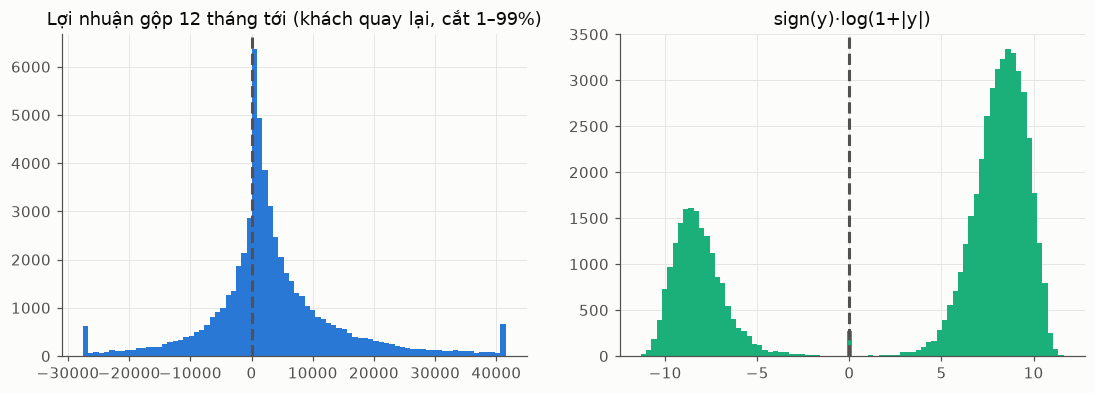

skew trước: 0.73 | sau: -0.82 | khối âm: 0.299 | khối dương: 0.697


In [3]:
z2 = slog(tr2.future_gross_profit)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
lo, hi = np.percentile(tr2.future_gross_profit, [1, 99])
ax[0].hist(tr2.future_gross_profit.clip(lo, hi), bins=80, color=viz.C[0]); ax[0].set_title("Lợi nhuận gộp 12 tháng tới (khách quay lại, cắt 1–99%)")
ax[1].hist(z2, bins=80, color=viz.C[2]); ax[1].set_title("sign(y)·log(1+|y|)")
for a in ax: a.axvline(0, color=viz.INK2, ls="--")
viz.save(fig, "07_clv_target"); plt.show()
print("skew trước:", round(tr2.future_gross_profit.skew(), 2), "| sau:", round(pd.Series(z2).skew(), 2),
      "| khối âm:", round((z2 < 0).mean(), 3), "| khối dương:", round((z2 > 0).mean(), 3))

## 3. Lọc biến theo kinh tế lượng (chỉ trên train)

Ma trận biến (`clv_model.design`): 30 biến số (biến đếm/tiền/ngày lấy `slog`), 4 cờ thiếu (khách 1 đơn chưa có chu kỳ, chưa đánh giá, chưa nhận hàng; điền 0 thay cho NaN), dummy của 6 biến phân loại (bỏ mức đầu). Ba bước:

1. **Liên quan với mục tiêu:** Spearman với mục tiêu; bỏ biến |ρ| < 0,01 (với ~59 nghìn khách, sai số chuẩn của ρ ≈ 0,004, nên 0,01 ≈ 2,4 lần sai số).
2. **Ma trận tương quan** giữa các biến còn lại (heatmap) để thấy các nhóm biến trùng thông tin.
3. **VIF:** bỏ lần lượt biến có VIF cao nhất cho tới khi mọi biến < 5. VIF tính bằng đường chéo của nghịch đảo ma trận tương quan (tương đương hồi quy từng biến lên các biến còn lại).

Hàm `select_features` dùng lại cho model chính (mục tiêu khác nên tập biến khác).

In [4]:
X_tr = design(tr2); X_tr = X_tr.loc[:, X_tr.std() > 0]
vif = lambda cols: pd.Series(np.diag(np.linalg.inv(X_tr[cols].corr().values)), index=cols)
def select_features(target):
    rho = X_tr.apply(lambda c: spearmanr(c, target)[0]).rename("spearman_với_mục_tiêu")
    step1 = list(rho[rho.abs() >= 0.01].index)
    dropped = [dict(biến=c, bước="1 liên quan", lý_do=f"|ρ| = {abs(rho[c]):.3f} < 0,01") for c in X_tr.columns if c not in step1]
    cols = step1[:]
    while (v := vif(cols)).max() >= 5:
        dropped.append(dict(biến=v.idxmax(), bước="3 VIF", lý_do=f"VIF = {v.max():.1f} (cao nhất lúc đó)")); cols.remove(v.idxmax())
    return rho, step1, cols, pd.DataFrame(dropped)
rho, step1, OLS_COLS, dropped_ols = select_features(z2)
print(f"{len(X_tr.columns)} biến → còn {len(step1)} sau bước 1 → {len(OLS_COLS)} sau VIF")
rho.reindex(rho.abs().sort_values(ascending=False).index).head(15).round(4)

55 biến → còn 26 sau bước 1 → 20 sau VIF


frequency        0.0642
monetary         0.0633
active_years     0.0564
tenure_days      0.0558
mean_gap_days   -0.0465
std_gap_days    -0.0304
orders_12m       0.0287
region_West      0.0257
no_review       -0.0255
return_rate      0.0245
region_East     -0.0243
n_categories     0.0242
recency_days    -0.0226
orders_6m        0.0222
avg_rating       0.0207
Name: spearman_với_mục_tiêu, dtype: float64

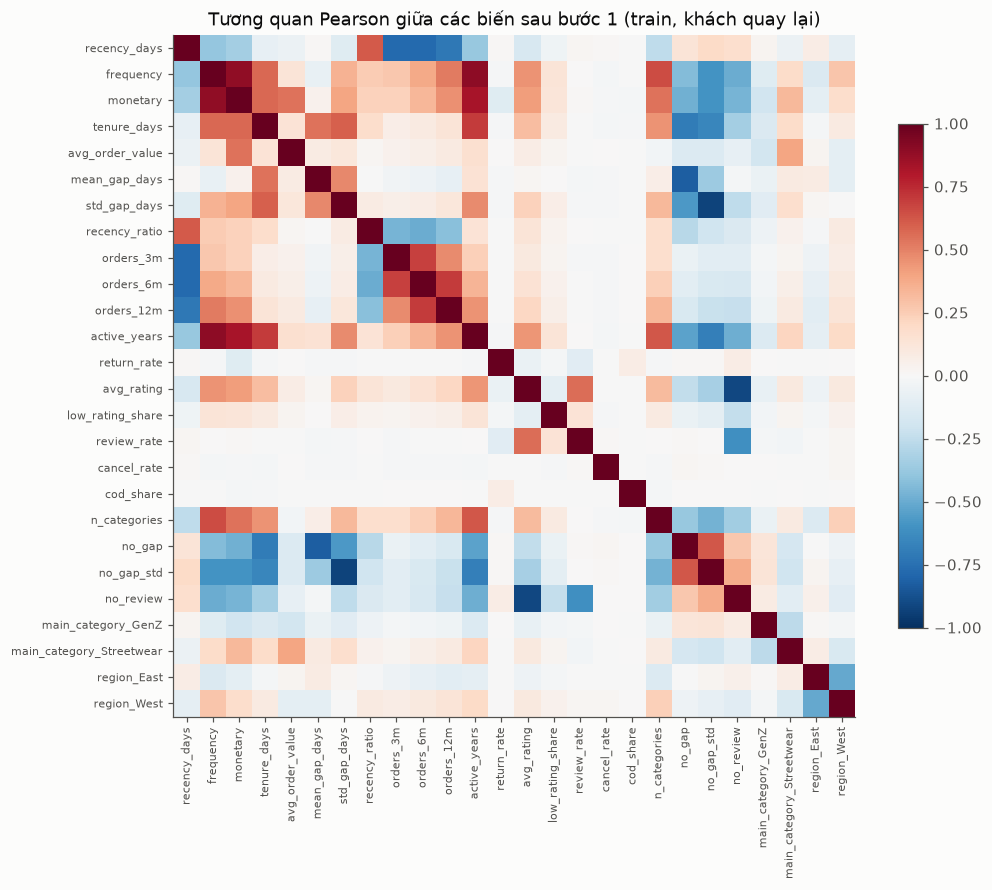

std_gap_days   no_gap_std     -0.927
avg_rating     no_review      -0.908
frequency      active_years    0.892
               monetary        0.884
mean_gap_days  no_gap         -0.827
monetary       active_years    0.825
recency_days   orders_6m      -0.780
               orders_3m      -0.779
               orders_12m     -0.712
tenure_days    no_gap         -0.702
               active_years    0.700
dtype: float64

In [5]:
corr = X_tr[step1].corr()
fig, ax = plt.subplots(figsize=(10, 8.5)); im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(step1)), step1, rotation=90, fontsize=7); ax.set_yticks(range(len(step1)), step1, fontsize=7)
fig.colorbar(im, shrink=.7); ax.set_title("Tương quan Pearson giữa các biến sau bước 1 (train, khách quay lại)")
viz.save(fig, "07_clv_corr"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack(); pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False).round(3)

In [6]:
pd.DataFrame({"VIF_trước": vif(step1), "VIF_sau": vif(OLS_COLS)}).sort_values("VIF_trước", ascending=False).round(2)

,VIF_trước,VIF_sau
monetary,72.86,NaN
frequency,60.90,NaN
no_gap,41.42,NaN
mean_gap_days,36.53,1.90
no_gap_std,22.48,NaN
no_review,17.17,NaN
std_gap_days,16.82,1.75
avg_rating,14.69,2.38
avg_order_value,14.58,1.23
active_years,8.85,4.21


In [7]:
dropped_ols

,biến,bước,lý_do
0,spend_trend,1 liên quan,"|ρ| = 0.005 < 0,01"
1,promo_share,1 liên quan,"|ρ| = 0.008 < 0,01"
2,avg_discount_rate,1 liên quan,"|ρ| = 0.010 < 0,01"
3,avg_delivery_days,1 liên quan,"|ρ| = 0.001 < 0,01"
4,late_delivery_share,1 liên quan,"|ρ| = 0.007 < 0,01"
5,installment_share,1 liên quan,"|ρ| = 0.001 < 0,01"
6,avg_installments,1 liên quan,"|ρ| = 0.008 < 0,01"
7,mobile_share,1 liên quan,"|ρ| = 0.002 < 0,01"
8,desktop_share,1 liên quan,"|ρ| = 0.005 < 0,01"
9,items_per_order,1 liên quan,"|ρ| = 0.000 < 0,01"


## 4. OLS (`statsmodels`, sai số chuẩn robust HC3)

HC3 được chọn vì mục 5 cho thấy phương sai thay đổi; hệ số không đổi, chỉ sai số chuẩn và p-value đổi.

In [8]:
ols = fit_ols(tr2, OLS_COLS); res = ols.model
print(f"R² = {res.rsquared:.4f} | R² hiệu chỉnh = {res.rsquared_adj:.4f} | n = {int(res.nobs)} | F (robust) p-value = {res.f_pvalue:.2g}")
coef = pd.DataFrame({"hệ_số": res.params, "SE_HC3": res.bse, "p_value": res.pvalues}).drop("const")
coef["có_ý_nghĩa_5%"] = coef.p_value < 0.05
coef.sort_values("p_value").round(4)

R² = 0.0016 | R² hiệu chỉnh = 0.0013 | n = 59088 | F (robust) p-value = 5e-12


,hệ_số,SE_HC3,p_value,có_ý_nghĩa_5%
tenure_days,0.5298,0.1421,0.0002,True
std_gap_days,-0.0908,0.0251,0.0003,True
n_categories,-0.5215,0.1613,0.0012,True
region_West,0.2564,0.0912,0.0049,True
mean_gap_days,-0.0891,0.0338,0.0083,True
region_East,-0.1601,0.0734,0.0292,True
active_years,0.3240,0.1706,0.0576,False
cancel_rate,-0.5139,0.3163,0.1042,False
main_category_GenZ,-0.5428,0.3779,0.1510,False
main_category_Streetwear,0.1508,0.1169,0.1972,False


## 5. Kiểm tra phần dư

Giả định của OLS: phần dư trung bình 0, phương sai không đổi, (để suy luận chính xác ở mẫu nhỏ) phân phối chuẩn.

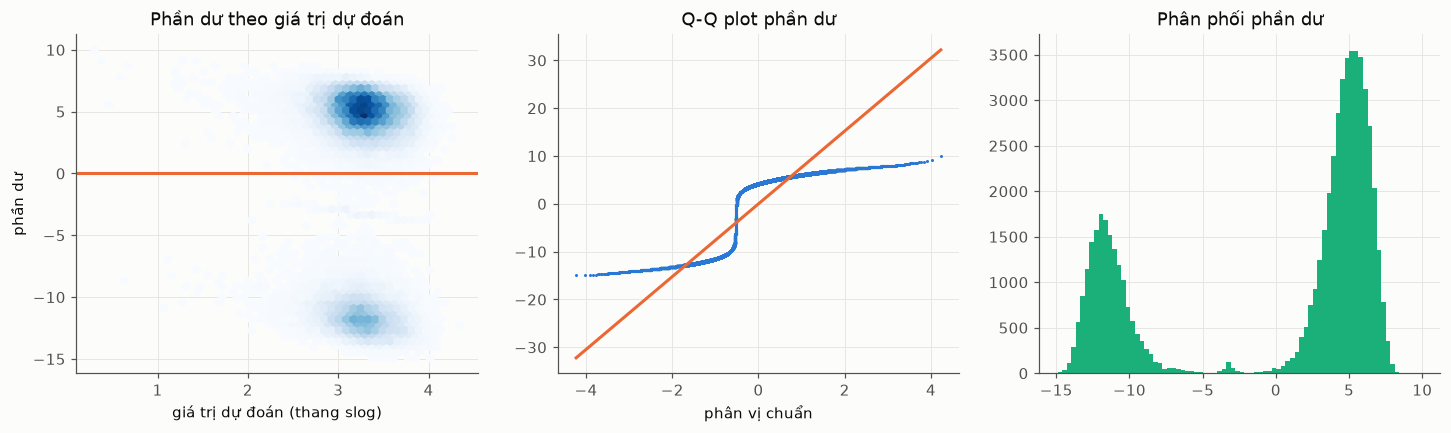

Breusch–Pagan: LM = 127.7, p = 1.1e-17 | skew phần dư -0.82, kurtosis -1.17


In [9]:
fitted, resid = res.fittedvalues, res.resid
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hexbin(fitted, resid, gridsize=50, cmap="Blues", mincnt=1); ax[0].axhline(0, color=viz.C[1]); ax[0].set_xlabel("giá trị dự đoán (thang slog)"); ax[0].set_ylabel("phần dư"); ax[0].set_title("Phần dư theo giá trị dự đoán")
(osm, osr), _ = probplot(resid, dist="norm"); ax[1].plot(osm, osr, ".", ms=2, color=viz.C[0]); ax[1].plot(osm, osm * resid.std() + resid.mean(), color=viz.C[1]); ax[1].set_title("Q-Q plot phần dư"); ax[1].set_xlabel("phân vị chuẩn")
ax[2].hist(resid, bins=80, color=viz.C[2]); ax[2].set_title("Phân phối phần dư")
viz.save(fig, "07_clv_residuals"); plt.show()
bp = het_breuschpagan(resid, res.model.exog)
print(f"Breusch–Pagan: LM = {bp[0]:.1f}, p = {bp[1]:.2g} | skew phần dư {resid.skew():.2f}, kurtosis {resid.kurt():.2f}")

## 6. Đổi ngược về tiền: smearing và mức tổng

Tổng CLV dự đoán so với tổng thực tế trên validation (khách quay lại): đổi ngược ngây thơ `slog⁻¹(ŷ)` so với smearing (phần dư train).

In [10]:
z_va = ols.predict_slog(va2)
naive, smeared = inv_slog(z_va), smear(z_va, ols.resid)
print(f"Tổng dự đoán / tổng thực tế (validation): ngây thơ {naive.sum() / y2.sum():.3f} | smearing {smeared.sum() / y2.sum():.3f}")
print(f"Smearing trên chính train: {smear(res.fittedvalues.values, ols.resid).sum() / tr2.future_gross_profit.sum():.3f}")
sets[["lợi_nhuận_TB", "trung_vị"]].round(0)

Tổng dự đoán / tổng thực tế (validation): ngây thơ 0.014 | smearing 2.175


Smearing trên chính train: 1.074


,lợi_nhuận_TB,trung_vị
tập,,
train 2019-01,2799.0,1598.0
train 2019-07,2502.0,1427.0
train 2020-01,4894.0,2392.0
validation 2021-01,2182.0,1438.0


Smearing sửa đúng phần nó phải sửa: đổi ngược ngây thơ đánh giá thấp gần như toàn bộ, còn trên train smearing khớp tổng. Phần lệch còn lại trên validation không do phép biến đổi mà do **mặt bằng lợi nhuận đổi theo năm**: năm nhãn 2020 (mốc 2020-01) có lợi nhuận trung bình cao gần gấp đôi các năm khác, kéo mức của cả tập train lên.

Cách xử lý giống bước hiệu chỉnh xác suất churn ở Task 6: **hiệu chỉnh mức tổng trên validation** bằng hệ số nhân `scale = Σy / Σŷ`, fit trên nửa A, đo trên nửa B. Hệ số nhân không đổi thứ tự xếp hạng.

## 7. Đánh giá OLS trên validation

### 7a. Phần 2: khách có quay lại

- **Hằng số:** lợi nhuận trung bình của khách quay lại trong train (mốc "không biết gì").
- **Baseline nghiệp vụ:** lợi nhuận gộp TB mỗi đơn quá khứ (`monetary × gross_margin_rate / frequency`) × số đơn 12 tháng trước (tối thiểu 1).
- **OLS** (biến đã lọc, smearing).

In [11]:
preds2 = {"Hằng số (TB train)": np.full(len(va2), tr2.future_gross_profit.mean()),
          "Baseline nghiệp vụ": (va2.monetary * va2.gross_margin_rate / va2.frequency * va2.orders_12m.clip(lower=1)).values,
          "OLS + smearing": smeared}
rows, SCALE = {}, {}
for k, p in preds2.items():
    SCALE[k] = y2[half].sum() / p[half].sum(); pb = p[~half] * SCALE[k]; e = pb - y2[~half]
    ci = sp_ci(y2, p) if p.std() > 0 else [np.nan, np.nan]
    rows[k] = dict(Spearman=spearmanr(p, y2)[0] if p.std() > 0 else np.nan, Spearman_CI_thấp=ci[0], Spearman_CI_cao=ci[1],
                   tổng_dự_đoán_trên_thực_tế=p.sum() / y2.sum(), scale=SCALE[k], tổng_sau_scale_nửa_B=pb.sum() / y2[~half].sum(),
                   MAE_B=np.abs(e).mean(), RMSE_B=np.sqrt((e ** 2).mean()))
part2 = pd.DataFrame(rows).T; part2.round(4)

,Spearman,Spearman_CI_thấp,Spearman_CI_cao,tổng_dự_đoán_trên_thực_tế,scale,tổng_sau_scale_nửa_B,MAE_B,RMSE_B
Hằng số (TB train),NaN,NaN,NaN,1.5355,0.6132,0.8875,7531.8390,12303.6594
Baseline nghiệp vụ,0.0036,-0.012,0.0173,1.4433,0.6466,0.8716,7934.2447,12567.8821
OLS + smearing,0.0259,0.011,0.0398,2.1747,0.4324,0.8852,7603.6990,12330.1226


### 7b. Toàn bộ khách

`CLV_kỳ_vọng = (1 − p_churn) × CLV_giữ_được` trên toàn bộ khách (khách churn có y = 0). Dòng "chỉ `1 − p_churn`" (hai phần với CLV hằng số) cho biết phần đóng góp riêng của CLV vào xếp hạng. `p_churn` trên validation đã được hiệu chỉnh bằng chính validation (Task 6); điều này chỉ ảnh hưởng mức tổng, không ảnh hưởng xếp hạng.

In [12]:
q = 1 - va.p_churn.values
full_preds = {"Hai phần: OLS": q * ols.predict(va) * SCALE["OLS + smearing"],
              "Hai phần: chỉ 1 − p_churn (CLV hằng số)": q * tr2.future_gross_profit.mean() * SCALE["Hằng số (TB train)"]}
full = pd.DataFrame({k: dict(Spearman=spearmanr(s, Y)[0], top10_lợi_nhuận=top10(s, Y), tổng_dự_đoán_trên_thực_tế=s.sum() / Y.sum())
                     for k, s in full_preds.items()}).T
full.loc["Hoàn hảo (tham chiếu)"] = [1.0, top10(Y, Y), 1.0]; full.round(4)

,Spearman,top10_lợi_nhuận,tổng_dự_đoán_trên_thực_tế
Hai phần: OLS,0.1304,0.2609,0.9443
Hai phần: chỉ 1 − p_churn (CLV hằng số),0.1507,0.2971,0.9415
Hoàn hảo (tham chiếu),1.0000,2.0073,1.0000


### 7c. Nhận ra khách làm lỗ

Precision / recall của nhóm dự đoán `CLV_giữ_được < 0`, và AUC của điểm CLV khi tách khách âm/dương.

In [13]:
neg = y2 < 0
loss = pd.DataFrame({k: dict(số_dự_đoán_âm=int((p < 0).sum()), precision=neg[p < 0].mean() if (p < 0).any() else np.nan,
                             recall=(p[neg] < 0).mean(), AUC_tách_âm=roc_auc_score(neg, -p) if p.std() > 0 else np.nan)
                     for k, p in preds2.items()}).T
print("Tỷ lệ khách quay lại có lợi nhuận âm (validation):", neg.mean().round(3)); loss.round(3)

Tỷ lệ khách quay lại có lợi nhuận âm (validation): 0.325


,số_dự_đoán_âm,precision,recall,AUC_tách_âm
Hằng số (TB train),0.0,NaN,0.000,NaN
Baseline nghiệp vụ,2498.0,0.315,0.141,0.494
OLS + smearing,433.0,0.279,0.022,0.499


### 7d. Phân tích lỗi của OLS

Chân dung 5% khách bị đánh giá quá cao và 5% bị đánh giá quá thấp nhiều nhất, so với toàn bộ.

In [14]:
e1 = va2.assign(clv=preds2["OLS + smearing"] * SCALE["OLS + smearing"]); e1["sai"] = e1.clv - e1.future_gross_profit
lo, hi = e1.sai.quantile([.05, .95])
e1["nhóm"] = np.select([e1.sai >= hi, e1.sai <= lo], ["quá cao (top 5%)", "quá thấp (top 5%)"], "còn lại")
cols = ["future_gross_profit", "clv", "frequency", "orders_12m", "recency_days", "monetary", "avg_order_value", "promo_share", "gross_margin_rate", "return_rate"]
prof = e1.groupby("nhóm")[cols].median(); prof.insert(0, "số khách", e1.nhóm.value_counts())
prof.loc["toàn bộ"] = [len(e1), *e1[cols].median()]; prof.round(3)

,số khách,future_gross_profit,clv,frequency,orders_12m,recency_days,monetary,avg_order_value,promo_share,gross_margin_rate,return_rate
nhóm,,,,,,,,,,,
còn lại,15457,1437.891,1984.641,11.0,1.0,315.0,239865.04,23220.960,0.375,0.103,0.000
quá cao (top 5%),859,-25708.508,2138.731,12.0,1.0,281.0,287282.79,23762.127,0.400,0.103,0.014
quá thấp (top 5%),859,30907.451,1984.221,12.0,1.0,280.0,281389.46,23933.478,0.385,0.098,0.012
toàn bộ,17175,1437.891,1989.625,11.0,1.0,311.0,244036.38,23281.392,0.375,0.103,0.000


# 8. Chẩn đoán: thành phần nào của lợi nhuận đoán được?

OLS gần như không xếp hạng được. Tách lợi nhuận 12 tháng tới = **số đơn** × **lợi nhuận mỗi đơn**, và lợi nhuận mỗi đơn = giá gốc − giá vốn − hoàn tiền − **giảm giá**. Đo Spearman của hai biến RFM mạnh nhất với từng thành phần (validation, khách quay lại).

In [15]:
comp = pd.DataFrame({"số đơn 12 tháng tới": va2.future_orders, "lợi nhuận giá gốc (chưa trừ giảm giá)": va2.future_profit_full_price,
                     "lợi nhuận gộp (mục tiêu của OLS)": va2.future_gross_profit})
pd.DataFrame({c: {"ρ với frequency": spearmanr(va2.frequency, comp[c])[0], "ρ với monetary": spearmanr(va2.monetary, comp[c])[0],
                  "tỷ lệ âm": (comp[c] < 0).mean()} for c in comp}).T.round(3)

,ρ với frequency,ρ với monetary,tỷ lệ âm
số đơn 12 tháng tới,0.310,0.293,0.000
lợi nhuận giá gốc (chưa trừ giảm giá),0.093,0.095,0.231
lợi nhuận gộp (mục tiêu của OLS),0.056,0.058,0.325


In [16]:
both = pd.concat([TRAIN, va]); both = both[both.churn == 0]
g = both.groupby("cutoff")
pd.DataFrame({"số đơn TB": g.future_orders.mean(), "lợi nhuận giá gốc / đơn": g.future_profit_full_price.sum() / g.future_orders.sum(),
              "lợi nhuận gộp / đơn": g.future_gross_profit.sum() / g.future_orders.sum()}).round(2)

,số đơn TB,lợi nhuận giá gốc / đơn,lợi nhuận gộp / đơn
cutoff,,,
2019-01-01,1.54,3150.80,1819.07
2019-07-01,1.49,3070.97,1677.11
2020-01-01,1.45,4774.48,3382.55
2021-01-01,1.46,2986.48,1489.98


Số đơn đoán được (ρ ≈ 0,3), lợi nhuận mỗi đơn thì không: dấu và độ lớn của nó phụ thuộc đơn năm sau có khuyến mãi, có bị hoàn không. Mặt bằng lợi nhuận mỗi đơn còn đổi theo năm (năm nhãn 2020 cao bất thường), trong khi số đơn TB ổn định hơn.

**Model chính:** dự báo phần đoán được (số đơn), phần không đoán được dùng trung bình:

`CLV_giữ_được = E[số đơn 12 tháng tới | quay lại] × lợi nhuận giá gốc TB mỗi đơn (theo danh mục chủ đạo) × scale`

Dùng lợi nhuận **giá gốc** (chưa trừ giảm giá) vì khoản giảm giá chính là chi phí voucher, được trừ riêng ở Task 10; tính cả ở đây là trừ hai lần.

# Model chính: hurdle Negative Binomial

## 9. Biến mục tiêu: số đơn thêm

Khách quay lại có ít nhất 1 đơn, nên mục tiêu là **số đơn thêm** `k = future_orders − 1 ≥ 0`; `E[số đơn] = 1 + E[k]`. Đây là biến đếm, nên dùng hồi quy đếm (link log) thay cho OLS: dự đoán trực tiếp trung bình, không cần smearing.

In [17]:
k_tr, k_va = tr2.future_orders.values - 1, va2.future_orders.values - 1
print(f"k: TB {k_tr.mean():.3f}, phương sai {k_tr.var():.3f} (tỷ số {k_tr.var() / k_tr.mean():.2f}; Poisson cần ≈ 1)")
pd.Series(k_tr).value_counts().sort_index().head(8).rename("số khách (train)").to_frame().T

k: TB 0.495, phương sai 0.750 (tỷ số 1.52; Poisson cần ≈ 1)


,0,1,2,3,4,5,6,7
số khách (train),39469,13253,4270,1373,474,141,66,24


## 10. Lọc biến cho model số đơn (cùng quy trình mục 3, mục tiêu là `k`)

In [18]:
rho_k, step1_k, NB_COLS, dropped_nb = select_features(k_tr)
print(f"{len(X_tr.columns)} biến → {len(step1_k)} sau bước 1 → {len(NB_COLS)} sau VIF, VIF max {vif(NB_COLS).max():.2f}")
display(rho_k.reindex(rho_k.abs().sort_values(ascending=False).index).head(12).round(4).to_frame())
dropped_nb

55 biến → 39 sau bước 1 → 31 sau VIF, VIF max 4.54


,spearman_với_mục_tiêu
frequency,0.3351
monetary,0.3144
active_years,0.2875
mean_gap_days,-0.2517
orders_12m,0.2088
n_categories,0.2085
recency_days,-0.1709
orders_6m,0.1542
no_review,-0.1527
tenure_days,0.1460


,biến,bước,lý_do
0,avg_delivery_days,1 liên quan,"|ρ| = 0.004 < 0,01"
1,installment_share,1 liên quan,"|ρ| = 0.007 < 0,01"
2,mobile_share,1 liên quan,"|ρ| = 0.006 < 0,01"
3,desktop_share,1 liên quan,"|ρ| = 0.005 < 0,01"
4,gross_margin_rate,1 liên quan,"|ρ| = 0.000 < 0,01"
5,gender_Male,1 liên quan,"|ρ| = 0.009 < 0,01"
6,gender_Non-binary,1 liên quan,"|ρ| = 0.001 < 0,01"
7,age_group_25-34,1 liên quan,"|ρ| = 0.001 < 0,01"
8,age_group_35-44,1 liên quan,"|ρ| = 0.000 < 0,01"
9,age_group_45-54,1 liên quan,"|ρ| = 0.000 < 0,01"


## 11. Poisson hay Negative Binomial?

Poisson giả định phương sai = trung bình. NB thêm tham số phân tán `α`: `Var = μ + α·μ²`, mô tả việc mỗi khách mua với tốc độ khác nhau. Kiểm tra bằng: tỷ số Pearson χ²/df của Poisson (≈ 1 nếu đúng), kiểm định LR cho `α = 0` (một phía, chia đôi p-value vì α nằm ở biên), AIC, và **rootogram**: tần suất quan sát của từng giá trị `k` so với tần suất model dự đoán.

In [19]:
Xc = sm.add_constant(design(tr2)[NB_COLS])
po = sm.GLM(k_tr, Xc, family=sm.families.Poisson()).fit()
nb = fit_nb(tr2, NB_COLS); nbr = nb.model
lr = 2 * (nbr.llf - po.llf)
print(f"Poisson: Pearson χ²/df = {po.pearson_chi2 / po.df_resid:.3f}, AIC = {po.aic:,.0f}")
print(f"NB:      α = {nbr.params['alpha']:.3f} (SE {nbr.bse['alpha']:.3f}), AIC = {nbr.aic:,.0f}")
print(f"LR test α = 0: LR = {lr:.1f}, p = {0.5 * chi2.sf(lr, 1):.2g}")

Poisson: Pearson χ²/df = 1.269, AIC = 106,119
NB:      α = 0.466 (SE 0.017), AIC = 104,616
LR test α = 0: LR = 1505.4, p = 0


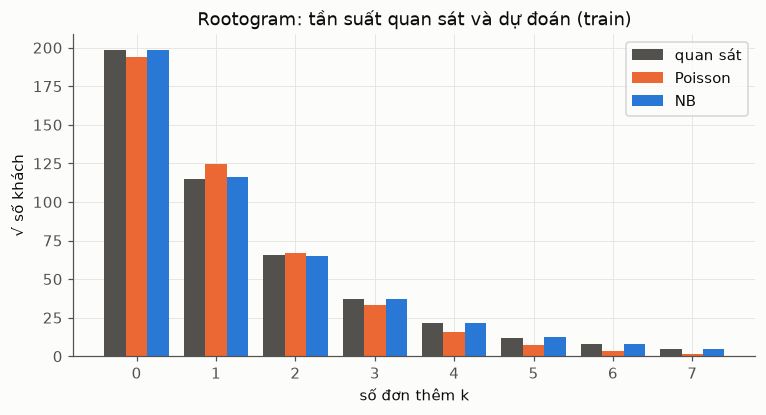

,0,1,2,3,4,5,6,7
quan sát,39469.0,13253.0,4270.0,1373.0,474.0,141.0,66.0,24.0
Poisson,37577.0,15604.0,4484.0,1106.0,250.0,53.0,11.0,2.0
NB,39394.0,13426.0,4190.0,1354.0,460.0,164.0,61.0,24.0


In [20]:
ks = np.arange(8)
mu_po = po.predict(Xc); mu_nb = nb.expected_orders(tr2) - 1
a = nbr.params["alpha"]; n_ = 1 / a
obs = np.array([(k_tr == x).sum() for x in ks])
exp_po = np.array([poisson.pmf(x, mu_po).sum() for x in ks]); exp_nb = np.array([nbinom.pmf(x, n_, n_ / (n_ + mu_nb)).sum() for x in ks])
fig, ax = plt.subplots(figsize=(8, 3.8)); w = .27
ax.bar(ks - w, np.sqrt(obs), w, color=viz.INK2, label="quan sát"); ax.bar(ks, np.sqrt(exp_po), w, color=viz.C[1], label="Poisson"); ax.bar(ks + w, np.sqrt(exp_nb), w, color=viz.C[0], label="NB")
ax.set_xlabel("số đơn thêm k"); ax.set_ylabel("√ số khách"); ax.set_title("Rootogram: tần suất quan sát và dự đoán (train)"); ax.legend()
viz.save(fig, "07_clv_rootogram"); plt.show()
pd.DataFrame({"quan sát": obs, "Poisson": exp_po.round(0), "NB": exp_nb.round(0)}, index=ks).T

## 12. Hệ số NB (sai số chuẩn robust HC0)

`exp(hệ số)` = **tỷ số tỷ lệ (IRR)**: số đơn thêm kỳ vọng nhân lên bao nhiêu khi biến tăng 1 đơn vị (với biến đã lấy `slog`: khi biến gốc tăng khoảng e ≈ 2,7 lần), giữ các biến khác cố định.

In [21]:
nb_coef = pd.DataFrame({"hệ_số": nbr.params, "SE_HC0": nbr.bse, "p_value": nbr.pvalues}).drop(["const", "alpha"])
nb_coef["IRR"] = np.exp(nb_coef.hệ_số); nb_coef["có_ý_nghĩa_5%"] = nb_coef.p_value < 0.05
print(f"Pseudo R² (McFadden) = {nbr.prsquared:.4f} | n = {int(nbr.nobs)}")
nb_coef.sort_values("p_value").round(4)

Pseudo R² (McFadden) = 0.0678 | n = 59088


,hệ_số,SE_HC0,p_value,IRR,có_ý_nghĩa_5%
orders_12m,0.4413,0.0172,0.0000,1.5547,True
recency_ratio,0.3626,0.0177,0.0000,1.4371,True
mean_gap_days,-0.1880,0.0109,0.0000,0.8287,True
active_years,0.6754,0.0436,0.0000,1.9647,True
cancel_rate,0.8140,0.0773,0.0000,2.2569,True
orders_3m,0.2041,0.0254,0.0000,1.2264,True
tenure_days,0.3604,0.0469,0.0000,1.4339,True
n_categories,0.2388,0.0370,0.0000,1.2697,True
spend_trend,0.0065,0.0012,0.0000,1.0065,True
avg_order_value,0.1327,0.0254,0.0000,1.1419,True


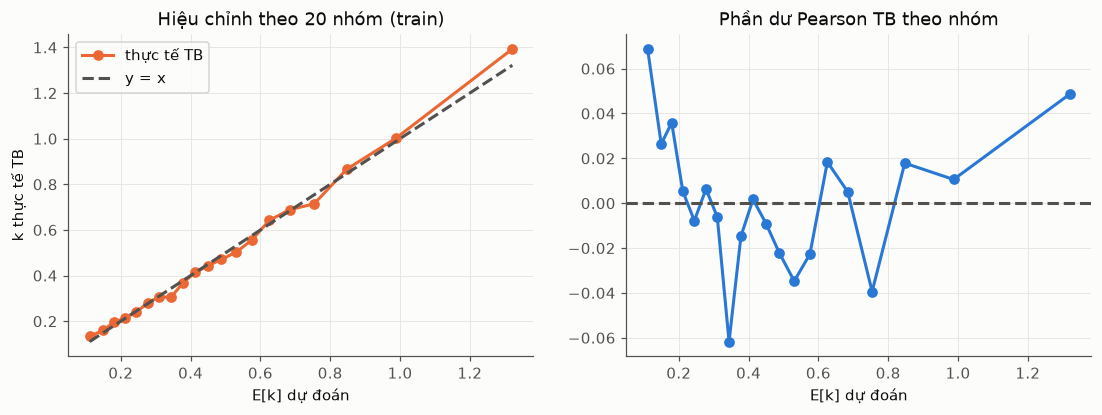

Phần dư Pearson: TB 0.001, phương sai 1.035 (≈ 1 nếu giả định phương sai NB đúng)


In [22]:
pr = (k_tr - mu_nb) / np.sqrt(mu_nb + a * mu_nb ** 2)   # phần dư Pearson theo phương sai NB
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
b = pd.qcut(mu_nb, 20, duplicates="drop"); gg = pd.DataFrame({"mu": mu_nb, "k": k_tr, "pr": pr}).groupby(b, observed=True).mean()
ax[0].plot(gg.mu, gg.k, "o-", color=viz.C[1], label="thực tế TB"); ax[0].plot(gg.mu, gg.mu, "--", color=viz.INK2, label="y = x")
ax[0].set_xlabel("E[k] dự đoán"); ax[0].set_ylabel("k thực tế TB"); ax[0].set_title("Hiệu chỉnh theo 20 nhóm (train)"); ax[0].legend()
ax[1].plot(gg.mu, gg.pr, "o-", color=viz.C[0]); ax[1].axhline(0, color=viz.INK2, ls="--"); ax[1].set_xlabel("E[k] dự đoán"); ax[1].set_title("Phần dư Pearson TB theo nhóm")
viz.save(fig, "07_clv_nb_fit"); plt.show()
print(f"Phần dư Pearson: TB {pr.mean():.3f}, phương sai {pr.var():.3f} (≈ 1 nếu giả định phương sai NB đúng)")

## 13. Lợi nhuận giá gốc mỗi đơn

`Σ lợi nhuận giá gốc / Σ số đơn` của khách quay lại trong train, theo danh mục chủ đạo (`clv_model.order_value_by_category`). Kiểm tra: dùng giá trị đơn quá khứ của chính khách (`avg_order_value`) thay cho trung bình danh mục có tốt hơn không.

In [23]:
nb_va = nb.expected_orders(va2)
yf2 = va2.future_profit_full_price.values
print("Lợi nhuận giá gốc mỗi đơn theo danh mục (train):", {k: round(v) for k, v in nb.value.items()})
print(f"Spearman với lợi nhuận giá gốc (validation): số đơn × TB danh mục {spearmanr(nb_va * nb.order_value(va2), yf2)[0]:.4f} | "
      f"số đơn × TB chung {spearmanr(nb_va, yf2)[0]:.4f} | số đơn × avg_order_value {spearmanr(nb_va * va2.avg_order_value, yf2)[0]:.4f}")

Lợi nhuận giá gốc mỗi đơn theo danh mục (train): {'Casual': 2607, 'GenZ': 2686, 'Outdoor': 3510, 'Streetwear': 3635, '_all': 3612}
Spearman với lợi nhuận giá gốc (validation): số đơn × TB danh mục 0.0903 | số đơn × TB chung 0.0920 | số đơn × avg_order_value 0.0622


## 14. So sánh trên validation

**Số đơn** (khách quay lại): NB, Poisson, LightGBM Poisson (36 biến), và mốc `frequency` (chỉ xếp hạng). **CLV theo tiền**: so với lợi nhuận giá gốc (đúng định nghĩa của model chính) và lợi nhuận gộp (để so với OLS ở mục 4). Mức tổng hiệu chỉnh bằng `scale` fit trên nửa A, đo trên nửa B, giống mục 7.

**Hai phần hay một phần (toàn bộ khách):** so `(1 − p_churn) × CLV_giữ_được` với **hồi quy một phần**: LightGBM Poisson dự đoán số đơn trên toàn bộ khách train (cả khách churn, số đơn = 0) × lợi nhuận giá gốc TB mỗi đơn, không hiệu chỉnh mức tổng.

In [24]:
lgp = fit_lgbm_poisson(tr2, list(FEATURES), LGB_PARAMS)
orders = {"NB": nb_va, "Poisson": 1 + po.predict(sm.add_constant(design(va2)[NB_COLS], has_constant="add")),
          "LightGBM Poisson": lgp.expected_orders(va2), "Hằng số (TB train)": np.full(len(va2), tr2.future_orders.mean())}
fo = va2.future_orders.values
pd.DataFrame({k: dict(Spearman=spearmanr(p, fo)[0] if p.std() > 0 else np.nan, MAE=np.abs(p - fo).mean(), RMSE=np.sqrt(((p - fo) ** 2).mean()),
                      tổng_dự_đoán_trên_thực_tế=p.sum() / fo.sum()) for k, p in orders.items()}
             | {"frequency (chỉ xếp hạng)": dict(Spearman=spearmanr(va2.frequency, fo)[0])}).T.round(4)

,Spearman,MAE,RMSE,tổng_dự_đoán_trên_thực_tế
NB,0.3005,0.5976,0.7900,1.0654
Poisson,0.3007,0.5977,0.7900,1.0666
LightGBM Poisson,0.3109,0.5727,0.7745,1.0154
Hằng số (TB train),NaN,0.6455,0.8315,1.0207
frequency (chỉ xếp hạng),0.3100,NaN,NaN,NaN


In [25]:
clv_raw = {"NB × lợi nhuận/đơn": nb.predict(va2), "LightGBM Poisson × lợi nhuận/đơn": lgp.predict(va2),
           "OLS lợi nhuận (mục 4)": preds2["OLS + smearing"], "Hằng số (TB train)": np.full(len(va2), tr2.future_profit_full_price.mean())}
rows, SCALE2 = {}, {}
for k, p in clv_raw.items():
    SCALE2[k] = yf2[half].sum() / p[half].sum(); pb = p[~half] * SCALE2[k]
    ci = sp_ci(yf2, p) if p.std() > 0 else [np.nan, np.nan]
    rows[k] = dict(Spearman_giá_gốc=spearmanr(p, yf2)[0] if p.std() > 0 else np.nan, CI_thấp=ci[0], CI_cao=ci[1],
                   Spearman_lợi_nhuận_gộp=spearmanr(p, y2)[0] if p.std() > 0 else np.nan,
                   tổng_trên_thực_tế_trước_scale=p.sum() / yf2.sum(), tổng_sau_scale_nửa_B=pb.sum() / yf2[~half].sum(),
                   MAE_B=np.abs(pb - yf2[~half]).mean())
cmp2 = pd.DataFrame(rows).T; cmp2.round(4)

,Spearman_giá_gốc,CI_thấp,CI_cao,Spearman_lợi_nhuận_gộp,tổng_trên_thực_tế_trước_scale,tổng_sau_scale_nửa_B,MAE_B
NB × lợi nhuận/đơn,0.0903,0.0775,0.1029,0.0532,1.2903,0.9522,7256.6999
LightGBM Poisson × lợi nhuận/đơn,0.0915,0.0780,0.1040,0.0537,1.2298,0.9537,7254.3020
OLS lợi nhuận (mục 4),0.0430,0.0286,0.0567,0.0259,1.0850,0.9526,7498.4814
Hằng số (TB train),NaN,NaN,NaN,NaN,1.2344,0.9550,7303.2867


In [26]:
d = np.array([spearmanr(clv_raw["LightGBM Poisson × lợi nhuận/đơn"][i], yf2[i])[0] - spearmanr(clv_raw["NB × lợi nhuận/đơn"][i], yf2[i])[0] for i in boot])
D_CI = np.percentile(d, [2.5, 97.5])
print(f"Spearman (giá gốc) LightGBM Poisson − NB: {d.mean():+.4f}, CI95 [{D_CI[0]:+.4f}, {D_CI[1]:+.4f}]")

Spearman (giá gốc) LightGBM Poisson − NB: +0.0011, CI95 [-0.0026, +0.0053]


In [27]:
YF = va.future_profit_full_price.values
one_m = lgb.LGBMRegressor(objective="poisson", **LGB_PARAMS, random_state=0, verbose=-1, n_jobs=-1).fit(TRAIN[list(FEATURES)], TRAIN.future_orders)
full2 = {"Hai phần: NB": q * nb.predict(va) * SCALE2["NB × lợi nhuận/đơn"],
         "Hai phần: LightGBM Poisson": q * lgp.predict(va) * SCALE2["LightGBM Poisson × lợi nhuận/đơn"],
         "Hai phần: OLS lợi nhuận": q * ols.predict(va) * SCALE2["OLS lợi nhuận (mục 4)"],
         "Hai phần: chỉ 1 − p_churn (CLV hằng số)": q * SCALE2["Hằng số (TB train)"] * tr2.future_profit_full_price.mean(),
         "Một phần: LightGBM Poisson số đơn × lợi nhuận/đơn": one_m.predict(va[list(FEATURES)]) * nb.value["_all"]}
full_tab = pd.DataFrame({k: dict(Spearman_giá_gốc=spearmanr(s, YF)[0], top10_giá_gốc=top10(s, YF), Spearman_lợi_nhuận_gộp=spearmanr(s, Y)[0],
                                 top10_lợi_nhuận_gộp=top10(s, Y), tổng_trên_thực_tế=s.sum() / YF.sum()) for k, s in full2.items()}).T
full_tab.round(4)

,Spearman_giá_gốc,top10_giá_gốc,Spearman_lợi_nhuận_gộp,top10_lợi_nhuận_gộp,tổng_trên_thực_tế
Hai phần: NB,0.2364,0.2829,0.1504,0.2865,0.9758
Hai phần: LightGBM Poisson,0.2365,0.2840,0.1503,0.2856,0.9761
Hai phần: OLS lợi nhuận,0.2056,0.2524,0.1304,0.2609,0.9803
Hai phần: chỉ 1 − p_churn (CLV hằng số),0.2370,0.2891,0.1507,0.2971,0.9775
Một phần: LightGBM Poisson số đơn × lợi nhuận/đơn,0.2366,0.2811,0.1506,0.2819,1.3061


OLS lợi nhuận | thực tế TB nhóm thấp nhất / cao nhất: 3674 / 5116 (gấp 1.4 lần)
NB | thực tế TB nhóm thấp nhất / cao nhất: 3121 / 6146 (gấp 2.0 lần)


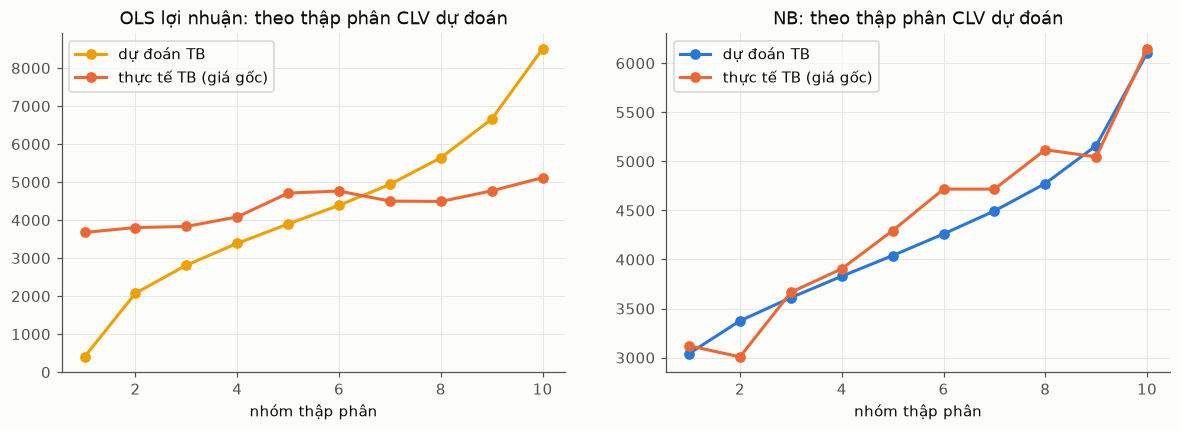

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a_, (name, p, col) in zip(ax, [("OLS lợi nhuận", clv_raw["OLS lợi nhuận (mục 4)"] * SCALE2["OLS lợi nhuận (mục 4)"], viz.C[3]),
                                   ("NB", clv_raw["NB × lợi nhuận/đơn"] * SCALE2["NB × lợi nhuận/đơn"], viz.C[0])]):
    dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False).values + 1
    gg = pd.DataFrame({"d": dec, "p": p, "y": yf2}).groupby("d").mean()
    a_.plot(gg.index, gg.p, "o-", color=col, label="dự đoán TB"); a_.plot(gg.index, gg.y, "o-", color=viz.C[1], label="thực tế TB (giá gốc)")
    a_.set_title(f"{name}: theo thập phân CLV dự đoán"); a_.set_xlabel("nhóm thập phân"); a_.legend()
    print(name, "| thực tế TB nhóm thấp nhất / cao nhất:", round(gg.y.iloc[0]), "/", round(gg.y.iloc[-1]), f"(gấp {gg.y.iloc[-1] / gg.y.iloc[0]:.1f} lần)")
viz.save(fig, "07_clv_deciles"); plt.show()

## 15. Chọn mô hình CLV

Quy tắc định trước: **ưu tiên NB** vì hệ số giải thích được (IRR) và đúng loại mô hình cho biến đếm; chỉ chọn LightGBM Poisson nếu Spearman CLV (giá gốc) hơn NB với khoảng tin cậy của mức chênh **không chứa 0**. `scale` fit lại trên toàn validation, giống bộ hiệu chỉnh churn.

In [29]:
CHOSEN = "lgbm_poisson" if D_CI[0] > 0 else "nb"
clv = lgp if CHOSEN == "lgbm_poisson" else nb
key = {"nb": "NB × lợi nhuận/đơn", "lgbm_poisson": "LightGBM Poisson × lợi nhuận/đơn"}[CHOSEN]
clv.scale = float(yf2.sum() / clv_raw[key].sum())
cfg = {"model": CHOSEN, "features": clv.cols, "params": LGB_PARAMS if CHOSEN == "lgbm_poisson" else None, "scale": clv.scale,
       "order_value": clv.value, "target": "future_profit_full_price (lợi nhuận giá gốc, chưa trừ giảm giá)",
       "validation": {"số_đơn_và_CLV": cmp2.round(4).to_dict("index"), "toàn_bộ": full_tab.round(4).to_dict("index"),
                      "ols_lợi_nhuận": part2.round(4).to_dict("index")}}
json.dump(cfg, open("../reports/clv_final.json", "w", encoding="utf8"), indent=1, ensure_ascii=False, default=float)
print("Chọn:", key, "| scale =", round(clv.scale, 4))

Chọn: NB × lợi nhuận/đơn | scale = 0.775


## 16. Phân tích lỗi (validation, model đã chọn)

Sai số theo **số đơn**: 5% khách mua nhiều hơn dự đoán nhất và 5% mua ít hơn dự đoán nhất, so với toàn bộ. Dùng validation, không dùng test.

In [30]:
e2 = va2.assign(E_đơn=clv.expected_orders(va2)); e2["sai_đơn"] = e2.future_orders - e2.E_đơn
lo, hi = e2.sai_đơn.quantile([.05, .95])
e2["nhóm"] = np.select([e2.sai_đơn >= hi, e2.sai_đơn <= lo], ["mua nhiều hơn dự đoán (top 5%)", "mua ít hơn dự đoán (top 5%)"], "còn lại")
cols = ["future_orders", "E_đơn", "frequency", "orders_12m", "recency_days", "tenure_days", "mean_gap_days", "monetary", "promo_share", "n_categories"]
prof2 = e2.groupby("nhóm")[cols].median(); prof2.insert(0, "số khách", e2.nhóm.value_counts())
prof2.loc["toàn bộ"] = [len(e2), *e2[cols].median()]; prof2.round(2)

,số khách,future_orders,E_đơn,frequency,orders_12m,recency_days,tenure_days,mean_gap_days,monetary,promo_share,n_categories
nhóm,,,,,,,,,,,
còn lại,15457,1.0,1.49,10.0,1.0,346.0,2842.0,250.90,227583.25,0.38,2.0
mua nhiều hơn dự đoán (top 5%),859,4.0,1.55,13.0,1.0,250.0,2904.0,194.50,311761.25,0.38,3.0
mua ít hơn dự đoán (top 5%),859,1.0,2.08,28.0,2.0,161.0,3030.0,100.30,627260.24,0.38,3.0
toàn bộ,17175,1.0,1.51,11.0,1.0,311.0,2864.0,236.67,244036.38,0.38,3.0


In [31]:
e2.groupby(pd.cut(e2.frequency, [0, 2, 5, 10, 20, 40, 1000]), observed=True).agg(
    khách=("E_đơn", "size"), số_đơn_thực_TB=("future_orders", "mean"), dự_đoán_TB=("E_đơn", "mean")).round(3)

,khách,số_đơn_thực_TB,dự_đoán_TB
frequency,,,
"(0, 2]",1027,1.105,1.153
"(2, 5]",2634,1.197,1.228
"(5, 10]",4767,1.306,1.407
"(10, 20]",5791,1.530,1.657
"(20, 40]",2607,1.878,1.999
"(40, 1000]",349,2.527,2.468


## 17. Sơ đồ giải thuật của mô hình hai phần

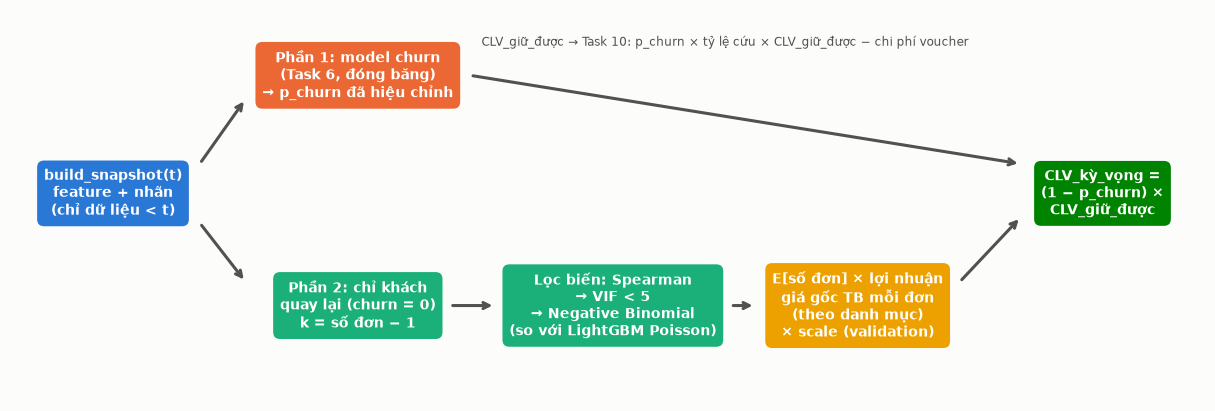

In [32]:
fig, ax = plt.subplots(figsize=(14, 4.6)); ax.axis("off"); ax.grid(False)
box = lambda x, y, t, c: ax.text(x, y, t, ha="center", va="center", fontsize=9, color="white", fontweight="bold", bbox=dict(boxstyle="round,pad=0.5", fc=c, ec="none"))
arrow = lambda x0, y0, x1, y1: ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color=viz.INK2, lw=2))
box(0, .5, "build_snapshot(t)\nfeature + nhãn\n(chỉ dữ liệu < t)", viz.C[0])
box(2.4, .9, "Phần 1: model churn\n(Task 6, đóng băng)\n→ p_churn đã hiệu chỉnh", viz.C[1])
box(2.4, .12, "Phần 2: chỉ khách\nquay lại (churn = 0)\nk = số đơn − 1", viz.C[2])
box(4.9, .12, "Lọc biến: Spearman\n→ VIF < 5\n→ Negative Binomial\n(so với LightGBM Poisson)", viz.C[2])
box(7.3, .12, "E[số đơn] × lợi nhuận\ngiá gốc TB mỗi đơn\n(theo danh mục)\n× scale (validation)", viz.C[3])
box(9.7, .5, "CLV_kỳ_vọng =\n(1 − p_churn) ×\nCLV_giữ_được", viz.C[5])
for a_ in [(0.85, .6, 1.3, .82), (0.85, .4, 1.3, .2), (3.3, .12, 3.75, .12), (6.05, .12, 6.3, .12), (8.3, .2, 8.9, .42), (3.5, .9, 8.9, .6)]: arrow(*a_)
ax.text(6, 1.0, "CLV_giữ_được → Task 10: p_churn × tỷ lệ cứu × CLV_giữ_được − chi phí voucher", ha="center", fontsize=8, color=viz.INK2)
ax.set_xlim(-1, 10.7); ax.set_ylim(-.2, 1.12)
viz.save(fig, "07_clv_algorithm"); plt.show()

## 18. Kết quả trên TEST 2022-01

Model NB, biến, lợi nhuận mỗi đơn, `scale` và model churn đều đã đóng băng ở mục 15. Chạy cùng các mốc tham chiếu: CLV hằng số (cùng quy trình scale) và hồi quy một phần.

In [33]:
from clean import clean_tables
from features import build_snapshot
from to_parquet import load_tables
te = build_snapshot(clean_tables(load_tables()), TEST_CUTOFF)
for c in CATEGORICAL:
    te[c] = pd.Categorical(te[c].astype(str).where(te[c].notna()), categories=TRAIN[c].cat.categories)
te2 = te[te.churn == 0]; fot, yft, ygt = te2.future_orders.values, te2.future_profit_full_price.values, te2.future_gross_profit.values
const = tr2.future_profit_full_price.mean() * SCALE2["Hằng số (TB train)"]
p2 = {key: clv.predict(te2), "Hằng số": np.full(len(te2), const)}
eo = clv.expected_orders(te2)
t_orders = dict(Spearman_số_đơn=spearmanr(eo, fot)[0], MAE_số_đơn=np.abs(eo - fot).mean(), tổng_số_đơn_dự_đoán_trên_thực_tế=eo.sum() / fot.sum())
t2 = pd.DataFrame({k: dict(Spearman_giá_gốc=spearmanr(p, yft)[0] if p.std() > 0 else np.nan, Spearman_lợi_nhuận_gộp=spearmanr(p, ygt)[0] if p.std() > 0 else np.nan,
                           MAE_giá_gốc=np.abs(p - yft).mean(), tổng_trên_thực_tế=p.sum() / yft.sum()) for k, p in p2.items()}).T
qt = 1 - cm.predict_proba(te); YFT, YT = te.future_profit_full_price.values, te.future_gross_profit.values
pf = {f"Hai phần: {key}": qt * clv.predict(te), "Hai phần: chỉ 1 − p_churn": qt * const,
      "Một phần: LightGBM Poisson số đơn × lợi nhuận/đơn": one_m.predict(te[list(FEATURES)]) * nb.value["_all"]}
tf = pd.DataFrame({k: dict(Spearman_giá_gốc=spearmanr(s, YFT)[0], top10_giá_gốc=top10(s, YFT), Spearman_lợi_nhuận_gộp=spearmanr(s, YT)[0],
                           top10_lợi_nhuận_gộp=top10(s, YT)) for k, s in pf.items()}).T
print(f"Test: {len(te)} khách, {len(te2)} quay lại |", {k: round(v, 4) for k, v in t_orders.items()})
cfg["test"] = {"số_đơn": t_orders, "phần_2": t2.round(4).to_dict("index"), "toàn_bộ": tf.round(4).to_dict("index")}
json.dump(cfg, open("../reports/clv_final.json", "w", encoding="utf8"), indent=1, ensure_ascii=False, default=float)
display(t2.round(4)); tf.round(4)

Test: 45880 khách, 16155 quay lại | {'Spearman_số_đơn': np.float64(0.3355), 'MAE_số_đơn': np.float64(0.6265), 'tổng_số_đơn_dự_đoán_trên_thực_tế': np.float64(1.0739)}


,Spearman_giá_gốc,Spearman_lợi_nhuận_gộp,MAE_giá_gốc,tổng_trên_thực_tế
NB × lợi nhuận/đơn,0.1272,0.0813,6374.1337,0.7306
Hằng số,NaN,NaN,6408.0678,0.6874


,Spearman_giá_gốc,top10_giá_gốc,Spearman_lợi_nhuận_gộp,top10_lợi_nhuận_gộp
Hai phần: NB × lợi nhuận/đơn,0.3008,0.2898,0.2100,0.2993
Hai phần: chỉ 1 − p_churn,0.3011,0.2920,0.2102,0.3053
Một phần: LightGBM Poisson số đơn × lợi nhuận/đơn,0.3007,0.2910,0.2098,0.3037


## 19. Nhận xét

**Bước thử: OLS hồi quy thẳng lên lợi nhuận gộp không dùng được, và lý do được chẩn đoán rõ.**

- OLS trên `slog(y)`: R² = 0,0016; phần dư hai đỉnh, Q-Q hình chữ S, Breusch–Pagan p = 1e-17. Spearman với lợi nhuận thực tế 0,026; không nhận ra khách làm lỗ (AUC ≈ 0,50). Khách bị dự đoán sai nhiều nhất có chân dung giống hệt phần còn lại.
- Nguyên nhân (mục 8): lợi nhuận = số đơn × lợi nhuận mỗi đơn. **Số đơn đoán được** (ρ = 0,31 với `frequency`). **Lợi nhuận mỗi đơn thì không**: 32,5% khách quay lại có lợi nhuận gộp âm, vì dấu của nó phụ thuộc đơn năm sau có khuyến mãi hay bị hoàn tiền không. Mặt bằng lợi nhuận mỗi đơn còn đổi theo năm (năm nhãn 2020: 3.380 so với ~1.500–1.800 các năm khác), còn số đơn TB ổn định (1,45–1,54).

**Model chính: hurdle Negative Binomial.** `CLV_giữ_được = E[số đơn | quay lại] × lợi nhuận giá gốc TB mỗi đơn theo danh mục × scale`.

- **Lọc biến:** 55 → 39 (bước 1 loại nhân khẩu học, thiết bị, trả góp, `gross_margin_rate`) → 31 sau VIF (loại `monetary`, `frequency`, `orders_6m`, `recency_days`, các cờ thiếu, một dummy danh mục), VIF max 4,5.
- **NB đúng loại mô hình:** dữ liệu phân tán quá mức (phương sai/TB = 1,52; Pearson χ²/df của Poisson 1,27). α = 0,47 (SE 0,017), LR test p ≈ 0, AIC giảm 1.500. Rootogram: Poisson dự đoán thiếu ở đuôi (k ≥ 4: 316 khách so với 729 quan sát), NB khớp từng giá trị. Phương sai phần dư Pearson 1,035 ≈ 1; hiệu chỉnh theo nhóm sát đường chéo. Pseudo R² 0,068.
- **Hệ số (IRR, đều có ý nghĩa 1%, giữ các biến khác cố định):** số đơn 12 tháng trước cao gấp ~2,7 lần thì số đơn thêm ×1,55; số năm có mua (`active_years`) ×1,96; thâm niên ×1,43; chu kỳ mua dài gấp ~2,7 lần thì ×0,83; mua nhiều danh mục ×1,27; giá trị đơn cao ×1,14; ưa khuyến mãi ×1,15. `cancel_rate` có IRR 2,26, cùng chiều trái trực giác như ở model churn và cùng nghi ngờ rò rỉ nhẹ (`order_status` là trạng thái cuối); giữ trong model nhưng không diễn giải. `recency_ratio` dương (×1,44) chỉ nên đọc chung với `mean_gap_days`.
- **So sánh trên validation:** dự báo số đơn: NB 0,300, LightGBM Poisson 0,311, Poisson 0,301. CLV theo tiền: NB Spearman 0,090 với lợi nhuận giá gốc (gấp đôi OLS: 0,043) và 0,053 với lợi nhuận gộp (OLS 0,026). Nhóm 10% CLV cao nhất có lợi nhuận thực tế gấp 2,0 lần nhóm thấp nhất (OLS: 1,4 lần). LightGBM Poisson chỉ hơn NB +0,001 (CI [−0,003, +0,005]) → **chọn NB** theo quy tắc định trước. Giá trị đơn theo danh mục và TB chung cho xếp hạng gần như nhau (0,090 so với 0,092, trong sai số); giữ theo danh mục vì phản ánh đúng mức biên khác nhau giữa danh mục (2.600 đến 3.600). Dùng `avg_order_value` của khách thì kém hơn (0,062).
- **Hai phần hay một phần:** hai phần NB (Spearman 0,236) ngang một phần LightGBM Poisson (0,237), nhưng một phần lệch mức tổng (1,31 so với 0,98), vì không tách được phần "có quay lại không" đã hiệu chỉnh xác suất.
- **Test 2022-01:** số đơn Spearman 0,336, tổng số đơn dự đoán/thực tế 1,07. CLV Spearman 0,127 (giá gốc) và 0,081 (gộp). Không có dấu hiệu overfit. Mức tổng tiền lệch (0,73) vì lợi nhuận mỗi đơn năm 2022 cao hơn năm 2021 dùng để hiệu chỉnh; **số đơn thì đúng mức**.
- **Phân tích lỗi:** khách mua **ít hơn** dự đoán nhiều nhất là khách "ruột" (trung vị 28 đơn, chu kỳ 100 ngày) nhưng năm sau chỉ mua 1 đơn, tức đang giảm dần mà dữ liệu quá khứ chưa cho thấy. Khách mua **nhiều hơn** dự đoán là khách tầm trung bất ngờ mua 4 đơn. Theo bậc số đơn quá khứ, dự đoán khớp sát thực tế (ví dụ 10–20 đơn: 1,66 so với 1,53).

**Kết luận cho báo cáo và Task 10:**

1. Model NB **có ý nghĩa ở phần nó dự báo được**: số đơn năm tới, kèm hệ số giải thích được (IRR). Khách mua đều, nhiều năm, nhiều danh mục thì quay lại mua nhiều hơn.
2. Đổi ra tiền, CLV xếp hạng tốt gấp đôi OLS nhưng vẫn yếu về tuyệt đối; phần còn lại là nhiễu của lợi nhuận mỗi đơn, không model nào khử được bằng dữ liệu này.
3. Xếp hạng lợi nhuận kỳ vọng trên **toàn bộ khách** vẫn gần như toàn bộ đến từ `p_churn`: hai phần NB ≈ CLV hằng số (validation 0,236 / 0,237; test 0,301 / 0,301).
4. Task 10 dùng `CLV_giữ_được` của NB (`clv_model.fit_final()`) và chỉ so sánh **tương đối** giữa các chiến lược, vì mức lợi nhuận tuyệt đối đổi theo năm.

**Hạn chế:** trong quá trình thử nghiệm, tập test đã được xem một lần trước khi chốt mô hình cuối; mọi lựa chọn (biến, tham số, lợi nhuận mỗi đơn, `scale`, quy tắc chọn model) đều dựa trên train và validation.
